RECTANGLE WEIR
  Slope (n)     = 1.4175   (theoretical: 1.5000)
  Intercept (c) = -1.1215
  R²            = 0.9972
  Cw            = 0.5120

V-NOTCH WEIR  (alpha = 90°)
  Slope (n)     = 2.4650   (theoretical: 2.5000)
  Intercept (c) = 0.1967
  R²            = 0.9984
  Cd            = 0.6658

Saved: Q1_calibration_curves.png


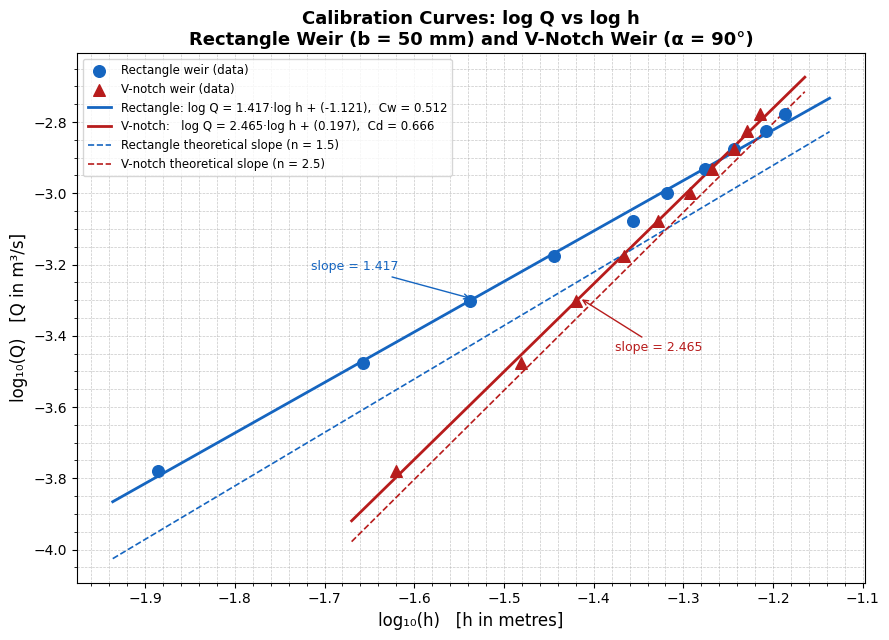

Saved: Q1_Q_vs_h_curves.png


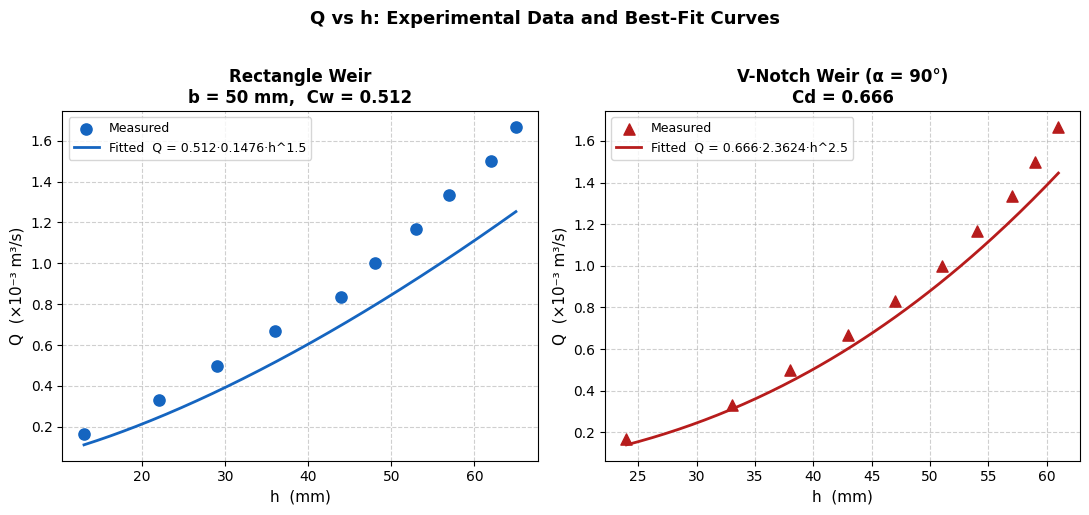


Done. All plots saved in current directory.

Summary for report:
  Rectangle weir:  Cw = 0.512,  slope = 1.417,  R² = 0.9972
  V-notch weir:    Cd = 0.666,  slope = 2.465,  R² = 0.9984


In [1]:
"""
Experiment #2: Discharge Over Weirs
Python script for Discussion Question 1 — Calibration Curves (log Q vs log h)
Run:  python weir_plots.py
Output: Q1_calibration_curves.png
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.stats import linregress

# ============================================================
# RAW EXPERIMENTAL DATA
# ============================================================
# Rectangle weir: b = 50 mm
rect_Q_lpm = np.array([100, 90, 80, 70, 60, 50, 40, 30, 20, 10])
rect_h_mm  = np.array([ 65, 62, 57, 53, 48, 44, 36, 29, 22, 13])

# V-notch weir: alpha = 90 degrees
vee_Q_lpm  = np.array([100, 90, 80, 70, 60, 50, 40, 30, 20, 10])
vee_h_mm   = np.array([ 61, 59, 57, 54, 51, 47, 43, 38, 33, 24])

# Unit conversion
rect_Q = rect_Q_lpm / 60000.0      # m³/s
rect_h = rect_h_mm  / 1000.0       # m
vee_Q  = vee_Q_lpm  / 60000.0      # m³/s
vee_h  = vee_h_mm   / 1000.0       # m

# Log values
log_rect_Q = np.log10(rect_Q)
log_rect_h = np.log10(rect_h)
log_vee_Q  = np.log10(vee_Q)
log_vee_h  = np.log10(vee_h)

# ============================================================
# LINEAR REGRESSION
# ============================================================
g = 9.81
b = 0.05          # m, rectangle width
alpha_deg = 90.0  # V-notch angle
alpha_rad = np.radians(alpha_deg)

# Theoretical constants
K_rect = (2/3) * b * np.sqrt(2 * g)          # = 0.14763
K_vee  = (8/15) * np.tan(alpha_rad/2) * np.sqrt(2 * g)  # = 2.3622

# Linear regression: log Q = n * log h + c
slope_r, intercept_r, r_r, _, _ = linregress(log_rect_h, log_rect_Q)
slope_v, intercept_v, r_v, _, _ = linregress(log_vee_h,  log_vee_Q)

# Discharge coefficients from intercept: c = log(C * K)  =>  C = 10^c / K
Cw = 10**intercept_r / K_rect
Cd = 10**intercept_v / K_vee

print("=" * 55)
print("RECTANGLE WEIR")
print(f"  Slope (n)     = {slope_r:.4f}   (theoretical: 1.5000)")
print(f"  Intercept (c) = {intercept_r:.4f}")
print(f"  R²            = {r_r**2:.4f}")
print(f"  Cw            = {Cw:.4f}")
print()
print("V-NOTCH WEIR  (alpha = 90°)")
print(f"  Slope (n)     = {slope_v:.4f}   (theoretical: 2.5000)")
print(f"  Intercept (c) = {intercept_v:.4f}")
print(f"  R²            = {r_v**2:.4f}")
print(f"  Cd            = {Cd:.4f}")
print("=" * 55)

# Fitted lines for plotting
h_range_r = np.linspace(log_rect_h.min() - 0.05, log_rect_h.max() + 0.05, 200)
h_range_v = np.linspace(log_vee_h.min()  - 0.05, log_vee_h.max()  + 0.05, 200)
fit_r = slope_r * h_range_r + intercept_r
fit_v = slope_v * h_range_v + intercept_v

# Theoretical lines (same h range, coefficients from regression)
theo_r = 1.5 * h_range_r + np.log10(Cw * K_rect)
theo_v = 2.5 * h_range_v + np.log10(Cd * K_vee)

# ============================================================
# FIGURE 1 — Combined log Q vs log h (Question 1 main plot)
# ============================================================
fig1, ax = plt.subplots(figsize=(9, 6.5))

# Data points
ax.scatter(log_rect_h, log_rect_Q,
           marker='o', s=70, color='#1565C0', zorder=5, label='Rectangle weir (data)')
ax.scatter(log_vee_h,  log_vee_Q,
           marker='^', s=70, color='#B71C1C', zorder=5, label='V-notch weir (data)')

# Best-fit lines
ax.plot(h_range_r, fit_r, color='#1565C0', linewidth=2,
        label=f'Rectangle: log Q = {slope_r:.3f}·log h + ({intercept_r:.3f}),  Cw = {Cw:.3f}')
ax.plot(h_range_v, fit_v, color='#B71C1C', linewidth=2,
        label=f'V-notch:   log Q = {slope_v:.3f}·log h + ({intercept_v:.3f}),  Cd = {Cd:.3f}')

# Theoretical slope reference lines (dashed)
ax.plot(h_range_r, theo_r, color='#1565C0', linewidth=1.2, linestyle='--',
        label='Rectangle theoretical slope (n = 1.5)')
ax.plot(h_range_v, theo_v, color='#B71C1C', linewidth=1.2, linestyle='--',
        label='V-notch theoretical slope (n = 2.5)')

# Annotations: slope labels
mid_r = len(h_range_r) // 2
mid_v = len(h_range_v) // 2
ax.annotate(f'slope = {slope_r:.3f}', xy=(h_range_r[mid_r], fit_r[mid_r]),
            xytext=(h_range_r[mid_r] - 0.18, fit_r[mid_r] + 0.08),
            fontsize=9, color='#1565C0',
            arrowprops=dict(arrowstyle='->', color='#1565C0', lw=1))
ax.annotate(f'slope = {slope_v:.3f}', xy=(h_range_v[mid_v], fit_v[mid_v]),
            xytext=(h_range_v[mid_v] + 0.04, fit_v[mid_v] - 0.15),
            fontsize=9, color='#B71C1C',
            arrowprops=dict(arrowstyle='->', color='#B71C1C', lw=1))

ax.set_xlabel('log₁₀(h)   [h in metres]', fontsize=12)
ax.set_ylabel('log₁₀(Q)   [Q in m³/s]',  fontsize=12)
ax.set_title('Calibration Curves: log Q vs log h\n'
             'Rectangle Weir (b = 50 mm) and V-Notch Weir (α = 90°)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=8.5, loc='upper left')
ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
ax.minorticks_on()

plt.tight_layout()
plt.savefig('Q1_calibration_curves.png', dpi=180, bbox_inches='tight')
print("\nSaved: Q1_calibration_curves.png")
plt.show()

# ============================================================
# FIGURE 2 — Q vs h (raw scale, for reference)
# ============================================================
fig2, axes = plt.subplots(1, 2, figsize=(11, 5))

# --- Rectangle weir ---
ax2 = axes[0]
h_cont_r = np.linspace(rect_h.min(), rect_h.max(), 200)
Q_fit_r   = Cw * K_rect * h_cont_r**1.5

ax2.scatter(rect_h * 1000, rect_Q * 1e3,
            marker='o', s=65, color='#1565C0', zorder=5, label='Measured')
ax2.plot(h_cont_r * 1000, Q_fit_r * 1e3,
         color='#1565C0', linewidth=2,
         label=f'Fitted  Q = {Cw:.3f}·{K_rect:.4f}·h^1.5')
ax2.set_xlabel('h  (mm)', fontsize=11)
ax2.set_ylabel('Q  (×10⁻³ m³/s)', fontsize=11)
ax2.set_title(f'Rectangle Weir\nb = 50 mm,  Cw = {Cw:.3f}', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(True, linestyle='--', alpha=0.6)

# --- V-notch weir ---
ax3 = axes[1]
h_cont_v = np.linspace(vee_h.min(), vee_h.max(), 200)
Q_fit_v   = Cd * K_vee * h_cont_v**2.5

ax3.scatter(vee_h * 1000, vee_Q * 1e3,
            marker='^', s=65, color='#B71C1C', zorder=5, label='Measured')
ax3.plot(h_cont_v * 1000, Q_fit_v * 1e3,
         color='#B71C1C', linewidth=2,
         label=f'Fitted  Q = {Cd:.3f}·{K_vee:.4f}·h^2.5')
ax3.set_xlabel('h  (mm)', fontsize=11)
ax3.set_ylabel('Q  (×10⁻³ m³/s)', fontsize=11)
ax3.set_title(f'V-Notch Weir (α = 90°)\nCd = {Cd:.3f}', fontsize=12, fontweight='bold')
ax3.legend(fontsize=9)
ax3.grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Q vs h: Experimental Data and Best-Fit Curves', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Q1_Q_vs_h_curves.png', dpi=180, bbox_inches='tight')
print("Saved: Q1_Q_vs_h_curves.png")
plt.show()

print("\nDone. All plots saved in current directory.")
print(f"\nSummary for report:")
print(f"  Rectangle weir:  Cw = {Cw:.3f},  slope = {slope_r:.3f},  R² = {r_r**2:.4f}")
print(f"  V-notch weir:    Cd = {Cd:.3f},  slope = {slope_v:.3f},  R² = {r_v**2:.4f}")